# Roads of Queensland
(c) Peter Corke 2021

Find the shortest driving route between two towns in Queensland, Australia.

This example appears in Robotics, Vision & Control (3rd edition) in §5.3 for the Python and MATLAB editions.


In [1]:
import json
from pgraph import UGraph, DGraph

The places and routes are in `queensland.json`; the graph is embedded, since each place has a UTM coordinate, and the cost of an edge is the driving distance. 

We start by loading the JSON file

In [2]:
with open('queensland.json', 'r') as f:
    data = json.loads(f.read())

Create an undirected graph

In [3]:
g = UGraph()

Create a vertex for every place, by providing the coordinate the resulting graph will be embedded

In [4]:
for name, info in data['places'].items():
    g.add_vertex(name=name, coord=info["utm"])

Create an edge for every route, and the cost is the driving distance

In [5]:
for route in data['routes']:
    g.add_edge(route['start'], route['end'], cost=route['distance'])

A summary of our graphs shows the number of vertices and edges

In [6]:
print(g)

UGraph: 20 vertices, 29 edges, 1 component


Print the graph edges in tabular form

In [7]:
for e in g.edges():
    print(e)

Edge{[Camooweal] ↔ [Mount Isa], cost=188}
Edge{[Mount Isa] ↔ [Cloncurry], cost=118}
Edge{[Cloncurry] ↔ [Hughenden], cost=401}
Edge{[Cloncurry] ↔ [Winton], cost=350}
Edge{[Hughenden] ↔ [Charters Towers], cost=248}
Edge{[Charters Towers] ↔ [Townsville], cost=135}
Edge{[Townsville] ↔ [Mackay], cost=388}
Edge{[Mackay] ↔ [Rockhampton], cost=334}
Edge{[Mackay] ↔ [Emerald], cost=384}
Edge{[Rockhampton] ↔ [Brisbane], cost=682}
Edge{[Rockhampton] ↔ [Emerald], cost=270}
Edge{[Brisbane] ↔ [Roma], cost=482}
Edge{[Roma] ↔ [Charleville], cost=266}
Edge{[Charleville] ↔ [Blackall], cost=305}
Edge{[Blackall] ↔ [Barcaldine], cost=106}
Edge{[Blackall] ↔ [Windorah], cost=530}
Edge{[Barcaldine] ↔ [Emerald], cost=307}
Edge{[Barcaldine] ↔ [Hughenden], cost=500}
Edge{[Barcaldine] ↔ [Longreach], cost=106}
Edge{[Longreach] ↔ [Windorah], cost=311}
Edge{[Longreach] ↔ [Winton], cost=180}
Edge{[Winton] ↔ [Hughenden], cost=216}
Edge{[Winton] ↔ [Boulia], cost=363}
Edge{[Winton] ↔ [Windorah], cost=487}
Edge{[Boulia] ↔

Solve for the minimum distance path, from Hughenden to Brisbane, using A*

In [8]:
p, length, parents = g.path_Astar('Hughenden', 'Brisbane', 
                                  verbose=True, summary=True)


FRONTIER: Hughenden(0)
EXPLORED: 
   expand Hughenden
      add Cloncurry to the frontier
      add Charters Towers to the frontier
      add Barcaldine to the frontier
      add Winton to the frontier
     move Hughenden to the explored list

FRONTIER: Cloncurry(1878), Charters Towers(1319), Barcaldine(1390), Winton(1371)
EXPLORED: Hughenden
   expand Charters Towers
      add Townsville to the frontier
     move Charters Towers to the explored list

FRONTIER: Cloncurry(1878), Barcaldine(1390), Winton(1371), Townsville(1493)
EXPLORED: Hughenden, Charters Towers
   expand Winton
      add Longreach to the frontier
      add Boulia to the frontier
      add Windorah to the frontier
     move Winton to the explored list

FRONTIER: Cloncurry(1878), Barcaldine(1390), Townsville(1493), Longreach(1385), Boulia(1995), Windorah(1762)
EXPLORED: Hughenden, Charters Towers, Winton
   expand Longreach
     move Longreach to the explored list

FRONTIER: Cloncurry(1878), Barcaldine(1390), Townsvill

The result is a list of `Vertex` objects

In [9]:
print(f"shortest path has length {length:.1f}:", 
      '->'.join([str(x.name) for x in p]))

shortest path has length 1659.0: Hughenden->Barcaldine->Blackall->Charleville->Roma->Brisbane


Plot the graph, and overlay the path

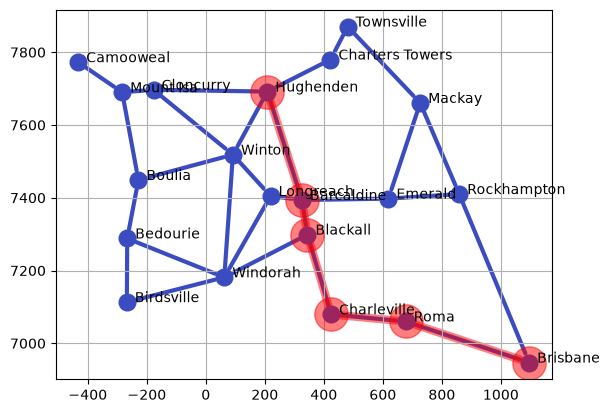

In [10]:
g.plot(block=None)  # block=None: show it once, with the path
g.highlight_path(p, alpha=0.5, scale=2, block=None)

Turn the vertex parent information into a tree, it's a dict that maps a vertex to its parent.

In [11]:
tree = DGraph.Dict(parents)
tree.showgraph()  # display it via the browser